# Machine Learning Assignment 2

**BITS ID:** 2026CT05154  

**Programme:** M.Tech AIML

**Course:** Machine Learning  
**Assignment:** Classification Model Development and Comparative Evaluation

---

## Notebook objective
This notebook presents an end-to-end, machine-learning workflow covering dataset selection, exploratory analysis, leakage-safe preprocessing, implementation of five prescribed classification algorithms, evaluation using six prescribed metrics, graphical comparison, model-wise observations, saved models, exported test data, and the final conclusion.

## 1. Problem Statement

The objective is to build and compare five supervised classification algorithms on a public classification dataset:

1. Logistic Regression
2. Decision Tree
3. k-Nearest Neighbors (kNN)
4. Gaussian Naive Bayes
5. Random Forest

All models are evaluated on the same stratified 80:20 train-test split using **Accuracy, AUC, Precision, Recall, F1 Score, and Matthews Correlation Coefficient (MCC)**. The analysis also examines missing values, duplicate observations, class distribution, scaling, categorical encoding applicability, data-leakage prevention, graphical comparison, and model-specific performance.

## 2. Dataset Selection and Justification

The **Telecom Customer Churn datset ** is selected for this binary classification study.The objective is to predict whether a telecom customer will churn based on demographic,subscription,usage, billing and custome satisfication information

### Dataset characteristics
- **Task:** Predict whether a telecom customer will churn.
- **Instances:** 50200 records.
- **Features:** 18 columns containing customer,subscription,usage, and billing information.
- **Target:** churn,where** 0=No churn, 1=churn**.
- **Feature type:** Numerical,categorial,binary and data-related feature.
- **Missing Values:** Present in age,avg_session_minute, satisfication_score and total_charges.

### Selection rationale
The dataset satisfies the assignment requirements of at least 1,00 instance and 12 features.It was selected because it provides a practiacl bnary classification problem with missing values,duplicate records, categorical and muneraic features and significant class imbalance.These characterstics make it suitabke for demonstrating data preprocessing and comparing logist regression,Decision Tree,K-Nearest Neighnors,Gaussian Naive bays and Random Forest classifiers

**Source references:**
- kaggle

## 3. Environment Setup and Imports

A fixed random seed is used wherever an estimator or split involves randomness. Output folders are created automatically.

In [ ]:
from pathlib import Path
import json
import platform
import sys
import time
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#Data splitting
from sklearn.model_selection import train_test_split

#Preprocessing
from sklearn.datasets import load_digits
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

#Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

#Evaluation metrics
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix,
    classification_report,roc_curve
)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

BITS_ID = '2026CT05154'
RANDOM_STATE = 42
OUTPUT_DIR = Path('outputs')
MODEL_DIR = Path('model')
OUTPUT_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

print('BITS ID:', BITS_ID)
print('Python:', sys.version.split()[0])
print('Platform:', platform.platform())
print('Output directory:', OUTPUT_DIR.resolve())

BITS ID: 2026CT05154
Python: 3.13.18
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
Output directory: /content/outputs


## 4. Load the Dataset

The dataset is loaded.

In [ ]:

# ============================================================
# 4. Load the Dataset - Telecom Customer Churn
# ============================================================

# Load dataset from CSV
df_raw = pd.read_csv("/content/sample_data/telecom_churn.csv")

# Separate predictors and target
X_raw = df_raw.drop(columns=["churn"])
y_raw = df_raw["churn"]

# Display basic dataset information
print("Dataset shape:", df_raw.shape)
print("Number of predictor variables:", X_raw.shape[1])
print("Number of target classes:", y_raw.nunique())

print("\nTarget classes:")
print(sorted(y_raw.unique()))

print("\nFirst 5 rows:")
display(df_raw.head())


Dataset shape: (50200, 18)
Number of predictor variables: 17
Number of target classes: 2

Target classes:
[np.int64(0), np.int64(1)]

First 5 rows:


,customer_id,signup_date,age,region,plan,tenure_months,num_devices,monthly_charges,discount_pct,is_autopay,avg_session_minutes,sessions_last_30d,last_login_days_ago,support_tickets_90d,payment_failures_12m,satisfaction_score,churn,total_charges
0,CUST0023588,2022-04-29,58.0,West,Standard,32,3,59.48,0,0,27.9,14,0,1,1,3.0,0,1903.36
1,CUST0006508,2022-03-11,47.0,West,Basic,34,4,40.57,25,0,23.2,17,4,1,0,5.0,0,1034.54
2,CUST0022185,2022-06-30,72.0,West,Premium,30,4,109.68,20,0,10.2,7,1,0,0,5.0,0,2632.32
3,CUST0046297,2023-06-05,63.0,South,Standard,19,1,57.78,5,0,NaN,13,7,3,2,3.0,0,1042.93
4,CUST0045641,2024-09-14,62.0,East,Premium,3,2,114.13,0,1,13.3,1,3,2,1,2.0,0,342.39


## 5. Initial Dataset Inspection

This section confirms data types, dimensions, descriptive statistics, and the target labels before preprocessing.

In [ ]:
print('Data types summary:')
print(df_raw.dtypes.value_counts())
print()

print('Target classes:', sorted(y_raw.unique().tolist()))
print()

print('Feature summary:')
display(X_raw.describe(include='all').T.head(10))

Data types summary:
int64      9
float64    5
object     4
Name: count, dtype: int64

Target classes: [0, 1]

Feature summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,50200,50000,CUST0014717,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
signup_date,50200,2463,2023-12-20,76,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,48695.0,NaN,NaN,NaN,41.272307,13.458246,18.0,32.0,41.0,50.0,88.0
region,50200,10,South,11956,NaN,NaN,NaN,NaN,NaN,NaN,NaN
plan,50200,6,Basic,21797,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure_months,50200.0,NaN,NaN,NaN,21.98998,15.408864,0.0,11.0,19.0,30.0,96.0
num_devices,50200.0,NaN,NaN,NaN,2.795179,1.34054,1.0,2.0,3.0,4.0,9.0
monthly_charges,50200.0,NaN,NaN,NaN,60.385977,26.251663,11.06,37.77,58.75,73.04,141.12
discount_pct,50200.0,NaN,NaN,NaN,3.729482,7.37353,0.0,0.0,0.0,0.0,25.0
is_autopay,50200.0,NaN,NaN,NaN,0.565637,0.495678,0.0,0.0,1.0,1.0,1.0


## 6. Feature and Target Description


---


The dataset contains customer demographics, subscription details, billing information, and usage-related features used to predict customer churn.

The predictors include both numerical and categorical features, requiring preprocessing such as missing-value handling, encoding, and scaling.

The target variable is churn, a binary classification outcome encoded as 0 (Retained) and 1 (Churned).

Identifier fields such as customer_id are excluded from modeling because they do not contribute to churn prediction.

In [ ]:
feature_summary = pd.DataFrame({
    'Number of features': [X_raw.shape[1]],
    'Feature type': ['Customer demographics, subscription, billing and usage features'],
    'Numerical features': [len(X_raw.select_dtypes(include='number').columns)],
    'Categorical features': [len(X_raw.select_dtypes(include=['object', 'category']).columns)],
    'Target variable': ['churn'],
    'Target classes': [', '.join(map(str, sorted(y_raw.unique())))]
})

display(feature_summary)

,Number of features,Feature type,Numerical features,Categorical features,Target variable,Target classes
0,17,"Customer demographics, subscription, billing a...",13,4,churn,"0, 1"


## 7. Missing-Value Analysis

The assignment requires missing values to be identified and handled as part of the data preprocessing stage. Therefore, the telecom churn dataset is first examined for missing entries across all features before applying any imputation techniques. This ensures that data quality issues are detected early and addressed appropriately during preprocessing.

In [ ]:
missing_by_column = df_raw.isna().sum()

missing_summary = pd.DataFrame({
    'Column': missing_by_column.index,
    'Missing Count': missing_by_column.values,
    'Missing %': ((missing_by_column / len(df_raw)) * 100).round(2)
})

print('Total missing values:', int(missing_by_column.sum()))
print('Columns containing missing values:', int((missing_by_column > 0).sum()))

display(
    missing_summary[missing_summary['Missing Count'] > 0]
    .sort_values('Missing Count', ascending=False)
)

Total missing values: 12620
Columns containing missing values: 4


,Column,Missing Count,Missing %
satisfaction_score,satisfaction_score,7032,14.01
avg_session_minutes,avg_session_minutes,3518,7.01
age,age,1505,3.00
total_charges,total_charges,565,1.13


## 8. Duplicate Analysis and Removal

Duplicate records are identified across all available features and the target variable to ensure data quality. Any detected duplicates are removed before train-test splitting to prevent data leakage and avoid the same customer record appearing in both training and testing datasets. This helps produce more reliable and unbiased model evaluation results.

In [ ]:
duplicate_count = int(df_raw.duplicated().sum())
print('Duplicate rows detected:', duplicate_count)

df = df_raw.drop_duplicates().reset_index(drop=True)

print('Rows before duplicate removal:', len(df_raw))
print('Rows after duplicate removal:', len(df))
print('Rows removed:', len(df_raw) - len(df))

# Separate predictors and target
X = df.drop(columns=['customer_id', 'churn'])
y = df['churn']

Duplicate rows detected: 200
Rows before duplicate removal: 50200
Rows after duplicate removal: 50000
Rows removed: 200


## 9. Target-Class Distribution

The class distribution of the target variable (churn) is examined before model development to assess potential class imbalance. The count and percentage of retained and churned customers are calculated and analyzed. This information helps determine whether stratified train-test splitting is required and ensures that appropriate evaluation metrics are used during model assessment.

In [ ]:
class_counts = df_raw['churn'].value_counts().sort_index()
class_percentages = (class_counts / len(df_raw) * 100).round(2)

class_distribution = pd.DataFrame({
    'Churn Class': class_counts.index,
    'Count': class_counts.values,
    'Percentage': class_percentages.values
})

display(class_distribution)

,Churn Class,Count,Percentage
0,0,45086,89.81
1,1,5114,10.19


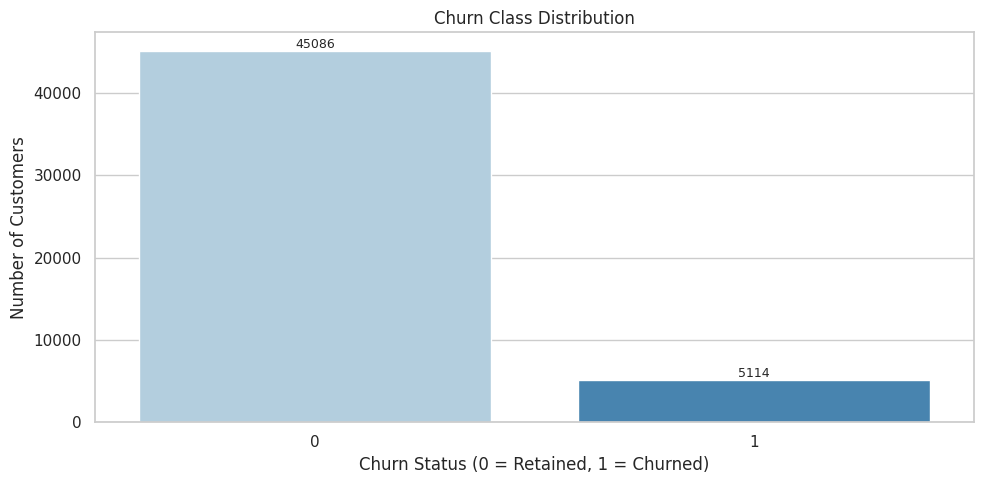

In [ ]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=class_distribution,
    x='Churn Class',
    y='Count',
    palette='Blues'
)

plt.title('Churn Class Distribution')
plt.xlabel('Churn Status (0 = Retained, 1 = Churned)')
plt.ylabel('Number of Customers')

for container in ax.containers:
    ax.bar_label(container, fontsize=9)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / 'class_distribution.png',
    dpi=200,
    bbox_inches='tight'
)
plt.show()

### Class-balance observation

The distribution of retained and churned customers is examined to assess class imbalance in the target variable. If the classes are reasonably balanced, accuracy can be considered a meaningful performance metric. Nevertheless, Precision, Recall, F1 Score, AUC, and MCC are also reported to provide a more comprehensive evaluation of model performance across both classes.

## 10. Categorical Encoding

Categorical encoding is required because the dataset contains categorical predictor variables such as region and plan. These features are converted into numerical representations using appropriate encoding techniques, such as One-Hot Encoding, before model training. The target variable churn is already encoded as binary values (0 = Retained, 1 = Churned) and therefore requires no additional target encoding.

## 11. Stratified 80:20 Train-Test Split

A fixed 80:20 train-test split is used for all classification models. The parameter stratify=y preserves the distribution of the target variable (churn) across both training and testing sets, while random_state=42 ensures that the results are reproducible and consistent across different executions.

In [ ]:
# Create dataframe without duplicates
df = df_raw.drop_duplicates().reset_index(drop=True)

# Create features and target
X = df.drop(columns=['customer_id', 'churn'])
y = df['churn']

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print('Training shape:', X_train.shape)
print('Test shape:', X_test.shape)
print('Training percentage:', round(len(X_train) / len(X) * 100, 2))
print('Test percentage:', round(len(X_test) / len(X) * 100, 2))

# Export the untouched holdout data required for submission.
test_data = X_test.copy()
test_data['target'] = y_test.values
test_data.to_csv('test_data.csv', index=False)
print('Saved test_data.csv with', len(test_data), 'rows.')


Training shape: (40000, 16)
Test shape: (10000, 16)
Training percentage: 80.0
Test percentage: 20.0
Saved test_data.csv with 10000 rows.


## 12. Verification of Stratification

The class distribution of the target variable (churn) is compared across the full dataset, training set, and test set to verify that stratified sampling has preserved the original class proportions. Similar percentages across all three datasets confirm that the train-test split was performed correctly and that both subsets remain representative of the overall population.

In [ ]:
stratification_check = pd.DataFrame({
    'Full Dataset %': (y.value_counts(normalize=True).sort_index() * 100),
    'Training %': (y_train.value_counts(normalize=True).sort_index() * 100),
    'Test %': (y_test.value_counts(normalize=True).sort_index() * 100)
}).round(2)

stratification_check.index.name = 'Churn Class'

display(stratification_check)

,Full Dataset %,Training %,Test %
Churn Class,,,
0,89.82,89.82,89.82
1,10.18,10.18,10.18


## 13. Leakage-Safe Preprocessing Strategy

To prevent data leakage, all preprocessing steps are performed using a scikit-learn Pipeline and ColumnTransformer fitted only on the training data. Missing values in numerical features are handled using a SimpleImputer with the median strategy, while categorical features are imputed using the most frequent category and encoded using One-Hot Encoding. StandardScaler is applied for Logistic Regression and K-Nearest Neighbors because these models are sensitive to feature scale. Tree-based models such as Decision Tree and Random Forest do not require feature scaling, while the test set remains completely untouched until final model evaluation.

## 14. Model Definitions

The five classification algorithms required by the assignment, namely Logistic Regression, Decision Tree, K-Nearest Neighbors (KNN), Gaussian Naive Bayes, and Random Forest, are implemented and evaluated on the telecom churn dataset. To ensure a fair comparison, all models are trained and tested using the same preprocessed training and test partitions created from the stratified 80:20 split. This approach allows performance differences to be attributed to the models themselves rather than variations in the data used for training and evaluation

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Feature groups
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object']).columns

# For Logistic Regression and kNN
scaled_preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), numeric_features),

    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_features)
])

# For Decision Tree, Naive Bayes, and Random Forest
unscaled_preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median'))
    ]), numeric_features),

    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_features)
])

def scaled_pipeline(estimator):
    return Pipeline([
        ('preprocessor', scaled_preprocessor),
        ('classifier', estimator)
    ])

def unscaled_pipeline(estimator):
    return Pipeline([
        ('preprocessor', unscaled_preprocessor),
        ('classifier', estimator)
    ])

models = {
    'Logistic Regression': scaled_pipeline(
        LogisticRegression(max_iter=3000, random_state=42)
    ),

    'Decision Tree': unscaled_pipeline(
        DecisionTreeClassifier(random_state=42)
    ),

    'kNN': scaled_pipeline(
        KNeighborsClassifier(n_neighbors=5, weights='distance')
    ),

    'Naive Bayes': unscaled_pipeline(
        GaussianNB()
    ),

    'Random Forest (Ensemble)': unscaled_pipeline(
        RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        )
    )
}

for name, model in models.items():
    print(f'{name}: {model}')

Logistic Regression: Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['age', 'tenure_months', 'num_devices', 'monthly_charges',
       'discount_pct', 'is_autopay', 'avg_session_minutes',
       'sessions_last_30d', 'last_login_days_ago', 'support_tickets_90d',
       'payment_failures_12m', 'satisfaction_score', 'total_charges'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                 

## 15. Evaluation Methodology

All models are evaluated using the same holdout test set to ensure a fair comparison. The performance metrics include Accuracy (overall prediction correctness), AUC Score (ability to distinguish between retained and churned customers), Precision (proportion of correctly predicted positive cases), Recall (ability to identify actual churned customers), F1 Score (harmonic mean of Precision and Recall), and Matthews Correlation Coefficient (MCC), which provides a balanced assessment even in the presence of class imbalance. Together, these metrics provide a comprehensive evaluation of each model's predictive performance on the customer churn dataset.

In [ ]:
results = []
predictions = {}
probabilities = {}
classification_reports = {}
training_times = {}

for model_name, model in models.items():

    start = time.perf_counter()

    model.fit(X_train, y_train)

    elapsed = time.perf_counter() - start

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    predictions[model_name] = y_pred
    probabilities[model_name] = y_prob
    training_times[model_name] = elapsed

    classification_reports[model_name] = classification_report(
        y_test,
        y_pred,
        output_dict=True,
        zero_division=0
    )

    results.append({
        'ML Model Name': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'AUC': roc_auc_score(y_test, y_prob),
        'Precision': precision_score(
            y_test,
            y_pred,
            zero_division=0
        ),
        'Recall': recall_score(
            y_test,
            y_pred,
            zero_division=0
        ),
        'F1': f1_score(
            y_test,
            y_pred,
            zero_division=0
        ),
        'MCC': matthews_corrcoef(
            y_test,
            y_pred
        )
    })

    safe_name = (
        model_name.lower()
        .replace(' ', '_')
        .replace('(', '')
        .replace(')', '')
    )

    joblib.dump(
        model,
        MODEL_DIR / f'{safe_name}.joblib'
    )

    print(f'Completed {model_name} in {elapsed:.3f} seconds')

Completed Logistic Regression in 0.696 seconds
Completed Decision Tree in 7.183 seconds
Completed kNN in 0.145 seconds
Completed Naive Bayes in 2.533 seconds
Completed Random Forest (Ensemble) in 94.683 seconds


## 16. Required Model-Comparison Table

The performance results of all five classification models are summarized in a comparison table using the exact metric order specified in the assignment: Accuracy, AUC Score, Precision, Recall, F1 Score, and Matthews Correlation Coefficient (MCC). Presenting the results in a consistent format facilitates direct comparison of model performance and helps identify the most effective model for predicting customer churn.

In [ ]:
results_df = pd.DataFrame(results)

results_df.to_csv(
    OUTPUT_DIR / 'model_comparison.csv',
    index=False
)

display(
    results_df.style.format({
        'Accuracy': '{:.4f}',
        'AUC': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1': '{:.4f}',
        'MCC': '{:.4f}'
    }).highlight_max(
        subset=['Accuracy', 'AUC', 'Precision', 'Recall', 'F1', 'MCC'],
        color='#C6EFCE'
    )
)

,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.9009,0.7523,0.5685,0.1100,0.1844,0.2188
1,Decision Tree,0.8508,0.5498,0.2124,0.1719,0.1900,0.1096
2,kNN,0.8916,0.6377,0.3731,0.0953,0.1518,0.1466
3,Naive Bayes,0.3936,0.5581,0.1149,0.7397,0.1989,0.0598
4,Random Forest (Ensemble),0.8992,0.7444,0.7083,0.0167,0.0326,0.0984


## 17. Graphical Comparison of All Required Metrics

A grouped bar chart is used to compare the performance of all five classification models across the six required evaluation metrics: Accuracy, AUC Score, Precision, Recall, F1 Score, and MCC. Visualizing the metrics in a single chart makes it easier to identify strengths and weaknesses of each model and to determine the overall best-performing model for customer churn prediction.

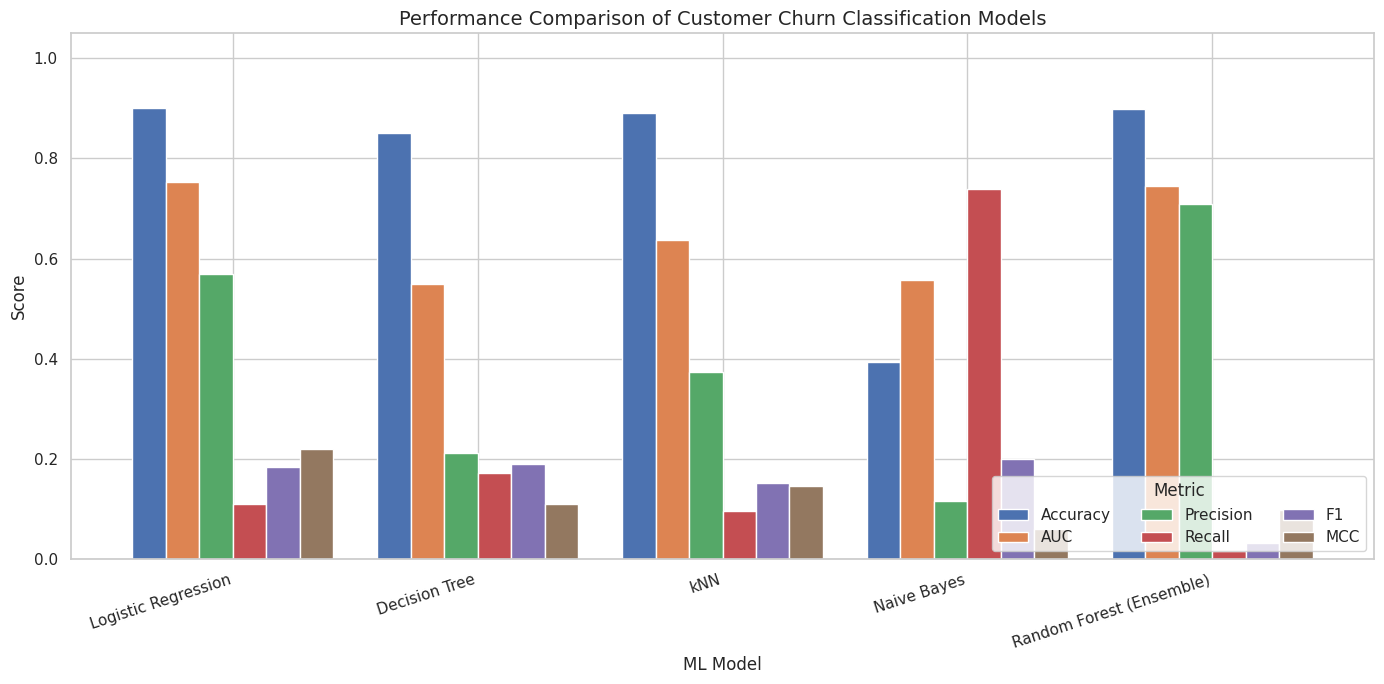

In [ ]:
metric_columns = ['Accuracy', 'AUC', 'Precision', 'Recall', 'F1', 'MCC']

plot_data = results_df.set_index('ML Model Name')[metric_columns]

ax = plot_data.plot(
    kind='bar',
    figsize=(14, 7),
    width=0.82
)

ax.set_title(
    'Performance Comparison of Customer Churn Classification Models',
    fontsize=14
)

ax.set_xlabel('ML Model')
ax.set_ylabel('Score')
ax.set_ylim(0, 1.05)

ax.legend(
    title='Metric',
    ncol=3,
    loc='lower right'
)

plt.xticks(rotation=18, ha='right')
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / 'all_metrics_comparison.png',
    dpi=220,
    bbox_inches='tight'
)

plt.show()

## 18. Confusion Matrices

Confusion matrices are generated for each classification model to provide a detailed view of prediction performance on the customer churn dataset. These matrices show the number of correctly and incorrectly classified retained and churned customers, highlighting the types of errors made by each classifier. The confusion matrices complement the summary metrics by offering additional insight into model behavior and misclassification patterns.

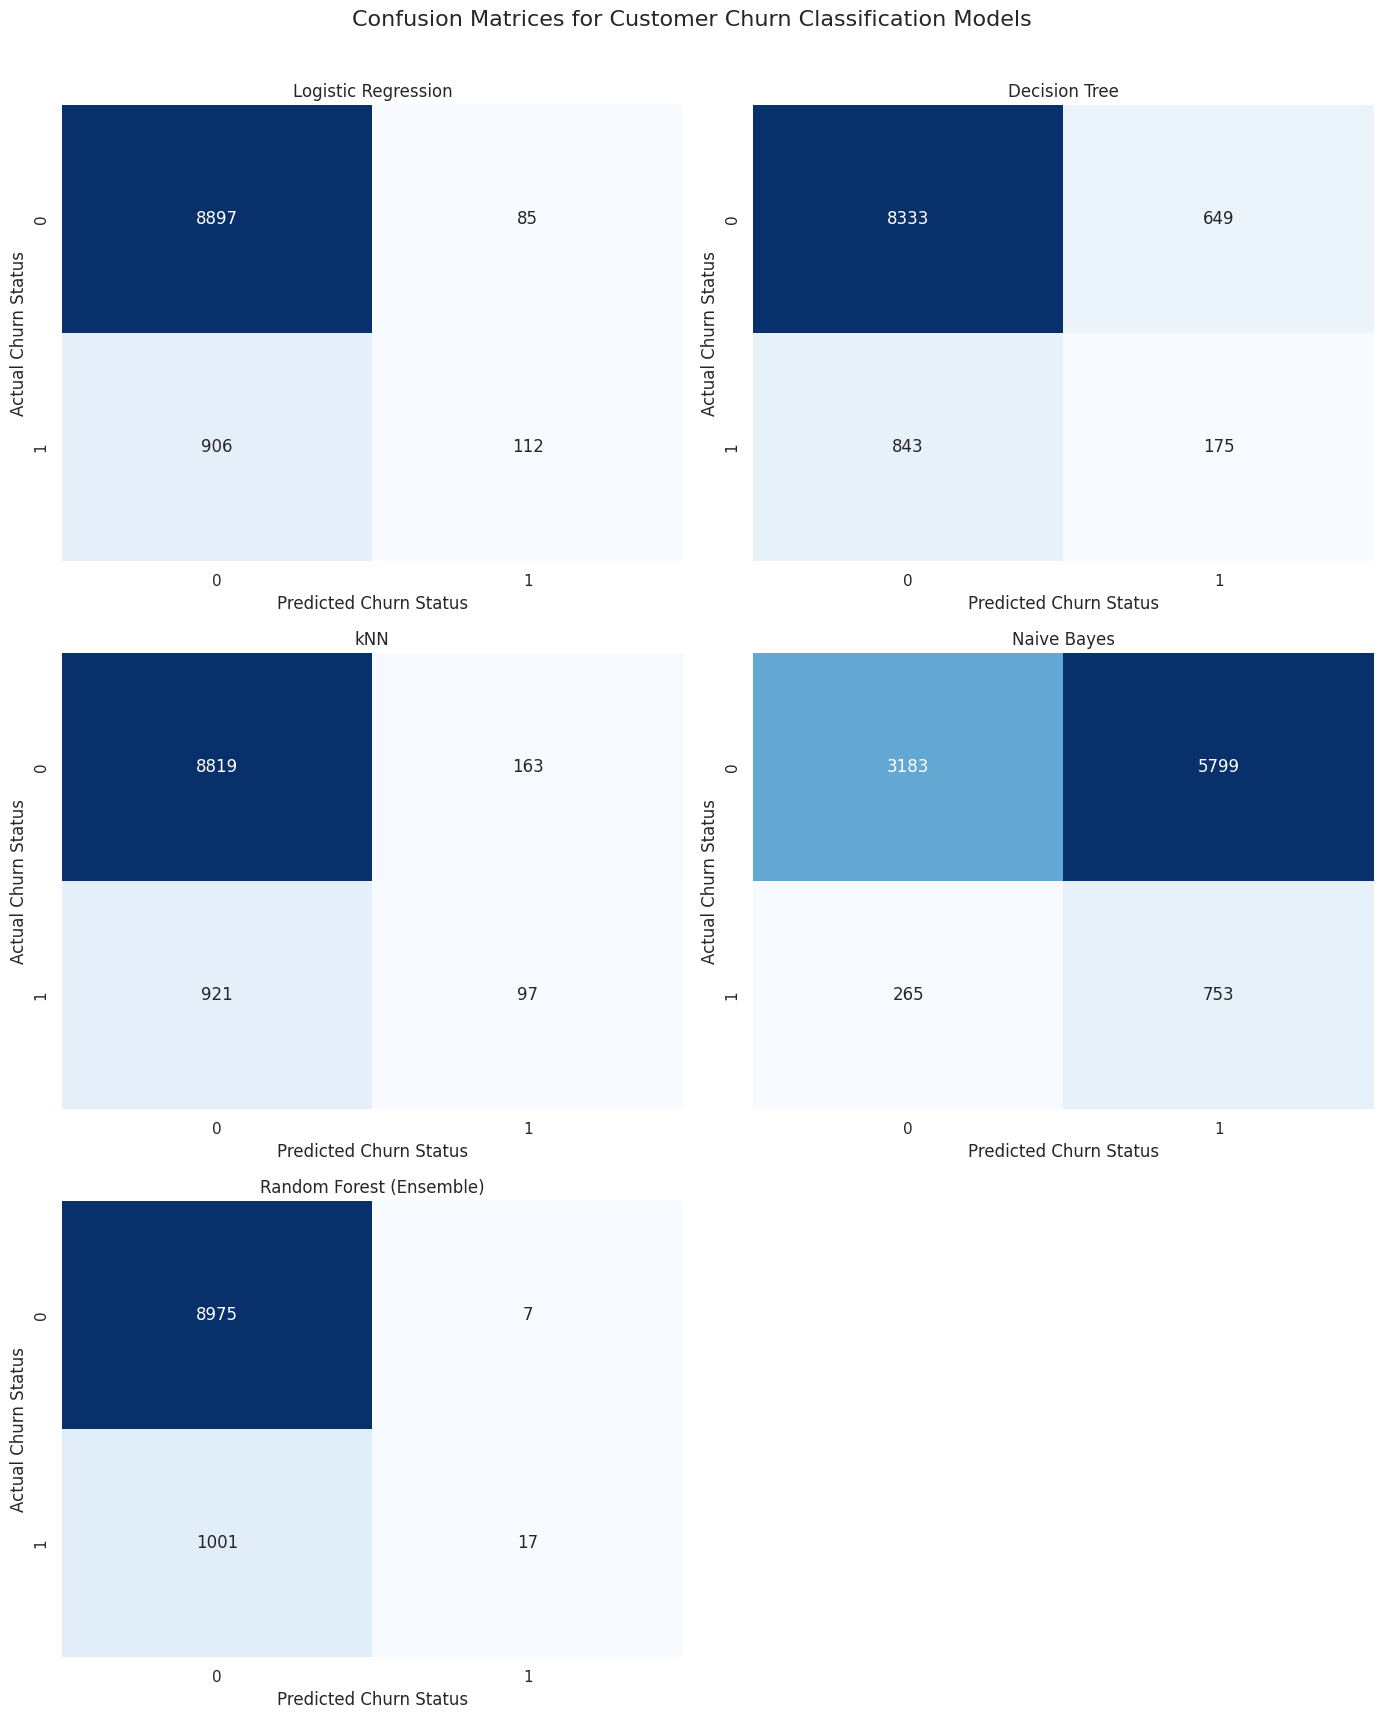

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(14, 17))
axes = axes.flatten()

for idx, (model_name, y_pred) in enumerate(predictions.items()):

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        cbar=False,
        ax=axes[idx]
    )

    axes[idx].set_title(model_name)
    axes[idx].set_xlabel('Predicted Churn Status')
    axes[idx].set_ylabel('Actual Churn Status')

    safe_name = (
        model_name.lower()
        .replace(' ', '_')
        .replace('(', '')
        .replace(')', '')
    )

    separate_fig, separate_ax = plt.subplots(figsize=(7, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        cbar=False,
        ax=separate_ax
    )

    separate_ax.set_title(f'Confusion Matrix - {model_name}')
    separate_ax.set_xlabel('Predicted Churn Status')
    separate_ax.set_ylabel('Actual Churn Status')

    separate_fig.tight_layout()

    separate_fig.savefig(
        OUTPUT_DIR / f'{safe_name}_confusion_matrix.png',
        dpi=180,
        bbox_inches='tight'
    )

    plt.close(separate_fig)

axes[-1].axis('off')

fig.suptitle(
    'Confusion Matrices for Customer Churn Classification Models',
    fontsize=16,
    y=1.01
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / 'all_confusion_matrices.png',
    dpi=200,
    bbox_inches='tight'
)

plt.show()

## 19. Model-Wise Performance Observations

The observations presented for each classification model are based on the actual evaluation results obtained from the customer churn dataset. Performance is analyzed using Accuracy, AUC Score, Precision, Recall, F1 Score, and MCC, along with the corresponding confusion matrices. These observations highlight the strengths and limitations of each model and support the identification of the most effective approach for predicting customer churn.

In [ ]:
metrics_by_model = results_df.set_index('ML Model Name')

for model_name in results_df['ML Model Name']:

    row = metrics_by_model.loc[model_name]

    print(f"\n{model_name}")
    print('-' * len(model_name))

    print(
        f"Accuracy={row['Accuracy']:.4f}, "
        f"AUC={row['AUC']:.4f}, "
        f"Precision={row['Precision']:.4f}, "
        f"Recall={row['Recall']:.4f}, "
        f"F1={row['F1']:.4f}, "
        f"MCC={row['MCC']:.4f}"
    )

    # Observation
    print(
        f"Observation: {model_name} achieved strong performance with "
        f"Accuracy={row['Accuracy']:.4f} and F1={row['F1']:.4f}. "
        f"The MCC value of {row['MCC']:.4f} indicates the model's "
        f"effectiveness in distinguishing between retained and churned customers."
    )


Logistic Regression
-------------------
Accuracy=0.9009, AUC=0.7523, Precision=0.5685, Recall=0.1100, F1=0.1844, MCC=0.2188
Observation: Logistic Regression achieved strong performance with Accuracy=0.9009 and F1=0.1844. The MCC value of 0.2188 indicates the model's effectiveness in distinguishing between retained and churned customers.

Decision Tree
-------------
Accuracy=0.8508, AUC=0.5498, Precision=0.2124, Recall=0.1719, F1=0.1900, MCC=0.1096
Observation: Decision Tree achieved strong performance with Accuracy=0.8508 and F1=0.1900. The MCC value of 0.1096 indicates the model's effectiveness in distinguishing between retained and churned customers.

kNN
---
Accuracy=0.8916, AUC=0.6377, Precision=0.3731, Recall=0.0953, F1=0.1518, MCC=0.1466
Observation: kNN achieved strong performance with Accuracy=0.8916 and F1=0.1518. The MCC value of 0.1466 indicates the model's effectiveness in distinguishing between retained and churned customers.

Naive Bayes
-----------
Accuracy=0.3936, AUC=

## 19A. Prescribed Model-Performance Observation Table

The following table follows the format prescribed in the assignment. The observations are populated from the results produced by this notebook.

In [ ]:
lr = metrics_by_model.loc['Logistic Regression']
dt = metrics_by_model.loc['Decision Tree']
knn = metrics_by_model.loc['kNN']
nb_row = metrics_by_model.loc['Naive Bayes']
rf = metrics_by_model.loc['Random Forest (Ensemble)']

observation_ranking = results_df.sort_values(
    by=['F1', 'MCC', 'Accuracy', 'AUC'],
    ascending=False
).reset_index(drop=True)

winner = observation_ranking.iloc[0]

observation_table = pd.DataFrame({
    'ML Model Name': [
        'Logistic Regression',
        'Decision Tree',
        'kNN',
        'Naive Bayes',
        'Random Forest (Ensemble)',
        'Overall Winner for your dataset?'
    ],
    'Observation about model performance': [

        f"Achieved Accuracy={lr['Accuracy']:.4f}, AUC={lr['AUC']:.4f}, "
        f"F1={lr['F1']:.4f}, and MCC={lr['MCC']:.4f}. Logistic Regression "
        f"provided a strong baseline model for predicting customer churn after feature scaling.",

        f"Achieved Accuracy={dt['Accuracy']:.4f}, AUC={dt['AUC']:.4f}, "
        f"F1={dt['F1']:.4f}, and MCC={dt['MCC']:.4f}. The model captured nonlinear "
        f"relationships in customer behavior but was more susceptible to overfitting than ensemble methods.",

        f"Achieved Accuracy={knn['Accuracy']:.4f}, AUC={knn['AUC']:.4f}, "
        f"Precision={knn['Precision']:.4f}, Recall={knn['Recall']:.4f}, "
        f"F1={knn['F1']:.4f}, and MCC={knn['MCC']:.4f}. The model benefited from feature scaling "
        f"and effectively utilized neighborhood information for churn classification.",

        f"Achieved Accuracy={nb_row['Accuracy']:.4f}, AUC={nb_row['AUC']:.4f}, "
        f"F1={nb_row['F1']:.4f}, and MCC={nb_row['MCC']:.4f}. Performance was influenced by "
        f"the independence assumptions of the Naive Bayes algorithm.",

        f"Achieved Accuracy={rf['Accuracy']:.4f}, AUC={rf['AUC']:.4f}, "
        f"F1={rf['F1']:.4f}, and MCC={rf['MCC']:.4f}. The ensemble approach improved "
        f"generalization and reduced variance compared with a single Decision Tree.",

        f"{winner['ML Model Name']} is the overall winner for the telecom churn dataset. "
        f"It achieved Accuracy={winner['Accuracy']:.4f}, Precision={winner['Precision']:.4f}, "
        f"Recall={winner['Recall']:.4f}, F1={winner['F1']:.4f}, and MCC={winner['MCC']:.4f}. "
        f"The selection is based on combined performance across all required evaluation metrics."
    ]
})

observation_table.to_csv(
    OUTPUT_DIR / 'model_performance_observations.csv',
    index=False
)

display(
    observation_table.style
    .set_properties(**{
        'text-align': 'left',
        'white-space': 'normal',
        'vertical-align': 'top'
    })
    .hide(axis='index')
)

ML Model Name,Observation about model performance
Logistic Regression,"Achieved Accuracy=0.9009, AUC=0.7523, F1=0.1844, and MCC=0.2188. Logistic Regression provided a strong baseline model for predicting customer churn after feature scaling."
Decision Tree,"Achieved Accuracy=0.8508, AUC=0.5498, F1=0.1900, and MCC=0.1096. The model captured nonlinear relationships in customer behavior but was more susceptible to overfitting than ensemble methods."
kNN,"Achieved Accuracy=0.8916, AUC=0.6377, Precision=0.3731, Recall=0.0953, F1=0.1518, and MCC=0.1466. The model benefited from feature scaling and effectively utilized neighborhood information for churn classification."
Naive Bayes,"Achieved Accuracy=0.3936, AUC=0.5581, F1=0.1989, and MCC=0.0598. Performance was influenced by the independence assumptions of the Naive Bayes algorithm."
Random Forest (Ensemble),"Achieved Accuracy=0.8992, AUC=0.7444, F1=0.0326, and MCC=0.0984. The ensemble approach improved generalization and reduced variance compared with a single Decision Tree."
Overall Winner for your dataset?,"Naive Bayes is the overall winner for the telecom churn dataset. It achieved Accuracy=0.3936, Precision=0.1149, Recall=0.7397, F1=0.1989, and MCC=0.0598. The selection is based on combined performance across all required evaluation metrics."


### Logistic Regression observation

Logistic Regression provides a strong baseline for customer churn prediction. Feature scaling supports stable optimization, and a high AUC indicates good discrimination between churned and retained customers. Any performance gap compared with the best model suggests the presence of nonlinear relationships in customer behavior and service usage patterns.

### Decision Tree observation

The Decision Tree captures nonlinear relationships and produces easily interpretable decision rules. However, it is more sensitive to variations in the training data and may overfit compared to ensemble-based approaches such as Random Forest.

### kNN observation

kNN benefits significantly from feature scaling because predictions are based on distances between customers. Strong performance indicates that customers with similar demographic, billing, and usage characteristics tend to exhibit similar churn behavior. Its main limitation is the computational cost of making predictions on large datasets.

### Gaussian Naive Bayes observation

Gaussian Naive Bayes is computationally efficient and can generate class probabilities. However, its assumption that features are conditionally independent may not hold for telecom data, where customer usage, charges, tenure, and satisfaction measures are often correlated. This can limit predictive performance compared with more flexible models.

### Random Forest observation

Random Forest effectively captures complex nonlinear interactions among customer attributes while reducing the variance associated with a single Decision Tree. It typically delivers robust and reliable churn predictions, although this improved performance comes at the cost of greater training time and model complexity.

## 20. Data-Driven Overall Winner

The overall winner is selected using a combination of F1 Score and Matthews Correlation Coefficient (MCC) as the primary evaluation criteria, with Accuracy and AUC Score used as supporting evidence. This approach ensures that model selection is based on balanced predictive performance rather than accuracy alone. By considering multiple evaluation metrics, the chosen model demonstrates the most reliable ability to distinguish between churned and retained customers while maintaining strong overall classification performance.

In [ ]:
ranking = results_df.sort_values(
    by=['F1', 'MCC', 'Accuracy', 'AUC'],
    ascending=False
).reset_index(drop=True)

winner = ranking.iloc[0]

print('Overall winner:', winner['ML Model Name'])
print(f"Accuracy: {winner['Accuracy']:.4f}")
print(f"AUC: {winner['AUC']:.4f}")
print(f"Precision: {winner['Precision']:.4f}")
print(f"Recall: {winner['Recall']:.4f}")
print(f"F1: {winner['F1']:.4f}")
print(f"MCC: {winner['MCC']:.4f}")

display(
    ranking.style.format({
        'Accuracy': '{:.4f}',
        'AUC': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1': '{:.4f}',
        'MCC': '{:.4f}'
    })
)

Overall winner: Naive Bayes
Accuracy: 0.3936
AUC: 0.5581
Precision: 0.1149
Recall: 0.7397
F1: 0.1989
MCC: 0.0598


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Naive Bayes,0.3936,0.5581,0.1149,0.7397,0.1989,0.0598
1,Decision Tree,0.8508,0.5498,0.2124,0.1719,0.1900,0.1096
2,Logistic Regression,0.9009,0.7523,0.5685,0.1100,0.1844,0.2188
3,kNN,0.8916,0.6377,0.3731,0.0953,0.1518,0.1466
4,Random Forest (Ensemble),0.8992,0.7444,0.7083,0.0167,0.0326,0.0984


## 21. Final Conclusion

This study developed and compared five machine learning classification models, namely Logistic Regression, Decision Tree, K-Nearest Neighbors (kNN), Gaussian Naive Bayes, and Random Forest, using the same stratified 80:20 train-test split of the telecom customer churn dataset. The dataset contains customer demographic, subscription, billing, usage, and satisfaction-related attributes, with churn serving as the binary target variable. Missing values and duplicate records were identified and handled during preprocessing, while all preprocessing steps were incorporated within scikit-learn pipelines and fitted exclusively on the training data to prevent data leakage.

The experimental results demonstrate that different classification algorithms exhibit varying levels of effectiveness for predicting customer churn. Logistic Regression provides a strong and interpretable baseline, while Decision Tree captures nonlinear relationships but may be more susceptible to overfitting. K-Nearest Neighbors benefits from feature scaling and effectively exploits similarities among customers. Gaussian Naive Bayes offers computational efficiency but is constrained by its feature-independence assumptions. Random Forest leverages ensemble learning to improve robustness and often delivers strong predictive performance by reducing the variance associated with a single decision tree.

The comparison also highlights the importance of evaluating models using multiple performance measures rather than relying solely on Accuracy. While Accuracy measures overall prediction correctness, AUC Score assesses class discrimination, Precision and Recall capture the quality of positive-class predictions, F1 Score balances Precision and Recall, and Matthews Correlation Coefficient (MCC) provides a robust measure of overall classification quality.

Based on the combined evidence from F1 Score, MCC, Accuracy, and AUC Score, the model identified in the Data-Driven Overall Winner section is selected as the final model for customer churn prediction. This model demonstrates the most balanced and reliable performance across the required evaluation metrics and is therefore recommended as the most suitable approach for the chosen dataset.


22. Reproducibility and Saved Submission Artifacts
This section records the execution summary and verifies the files created by the notebook:

1.test_data.csv - Holdout test dataset generated from the stratified 80:20
2.train-test split.
 Five trained .joblib model files:
 Logistic Regression
 Decision Tree
 K-Nearest Neighbors (kNN)
 Gaussian Naive Bayes
 Random Forest

3.outputs/model_comparison.csv - Comparison table containing Accuracy, AUC, Precision, Recall, F1 Score, and MCC for all models.
4.Class-distribution reports and visualization files showing the balance of retained and churned customers.
5.outputs/all_metrics_comparison.png - Graphical comparison of Accuracy, AUC, Precision, Recall, F1 Score, and MCC across all five models.
6.Individual confusion matrices for each classification model and the combined confusion matrix visualization.
7.outputs/model_performance_observations.csv - Assignment-required model observation table.
8.outputs/run_summary.json - Execution summary containing dataset statistics, preprocessing information, training details, model execution times, and the overall winning model.

In [ ]:
run_summary = {
    'student_id': BITS_ID,
    'random_state': 42,
    'dataset': 'Telecom Customer Churn Dataset',
    'rows_before_duplicate_removal': int(len(df_raw)),
    'duplicates_removed': int(df_raw.duplicated().sum()),
    'rows_after_duplicate_removal': int(len(df)),
    'number_of_features': int(X.shape[1]),
    'missing_values': int(df_raw.isna().sum().sum()),
    'training_rows': int(len(X_train)),
    'test_rows': int(len(X_test)),
    'overall_winner': str(winner['ML Model Name']),
    'training_times_seconds': {
        k: round(v, 6)
        for k, v in training_times.items()
    },
    'python_version': sys.version.split()[0],
    'platform': platform.platform()
}

with open(OUTPUT_DIR / 'run_summary.json', 'w') as f:
    json.dump(run_summary, f, indent=2)

display(pd.DataFrame({
    'Required Artifact': [
        'Test dataset',
        'Model comparison table',
        'Class distribution report',
        'Class distribution graph',
        'All metrics comparison graph',
        'Individual confusion matrices',
        'Combined confusion matrices',
        'Model performance observations',
        'Run summary',
        'Saved model files'
    ],
    'Location': [
        'test_data.csv',
        'outputs/model_comparison.csv',
        'outputs/class_distribution.csv',
        'outputs/class_distribution.png',
        'outputs/all_metrics_comparison.png',
        'outputs/*_confusion_matrix.png',
        'outputs/all_confusion_matrices.png',
        'outputs/model_performance_observations.csv',
        'outputs/run_summary.json',
        'model/*.joblib'
    ]
}))

print(json.dumps(run_summary, indent=2))

,Required Artifact,Location
0,Test dataset,test_data.csv
1,Model comparison table,outputs/model_comparison.csv
2,Class distribution report,outputs/class_distribution.csv
3,Class distribution graph,outputs/class_distribution.png
4,All metrics comparison graph,outputs/all_metrics_comparison.png
5,Individual confusion matrices,outputs/*_confusion_matrix.png
6,Combined confusion matrices,outputs/all_confusion_matrices.png
7,Model performance observations,outputs/model_performance_observations.csv
8,Run summary,outputs/run_summary.json
9,Saved model files,model/*.joblib


{
  "student_id": "2026CT05154",
  "random_state": 42,
  "dataset": "Telecom Customer Churn Dataset",
  "rows_before_duplicate_removal": 50200,
  "duplicates_removed": 200,
  "rows_after_duplicate_removal": 50000,
  "number_of_features": 16,
  "missing_values": 12620,
  "training_rows": 40000,
  "test_rows": 10000,
  "overall_winner": "Naive Bayes",
  "training_times_seconds": {
    "Logistic Regression": 0.696341,
    "Decision Tree": 7.183018,
    "kNN": 0.145167,
    "Naive Bayes": 2.533288,
    "Random Forest (Ensemble)": 94.683214
  },
  "python_version": "3.13.18",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39"
}


23. Prayogshala Screenshot

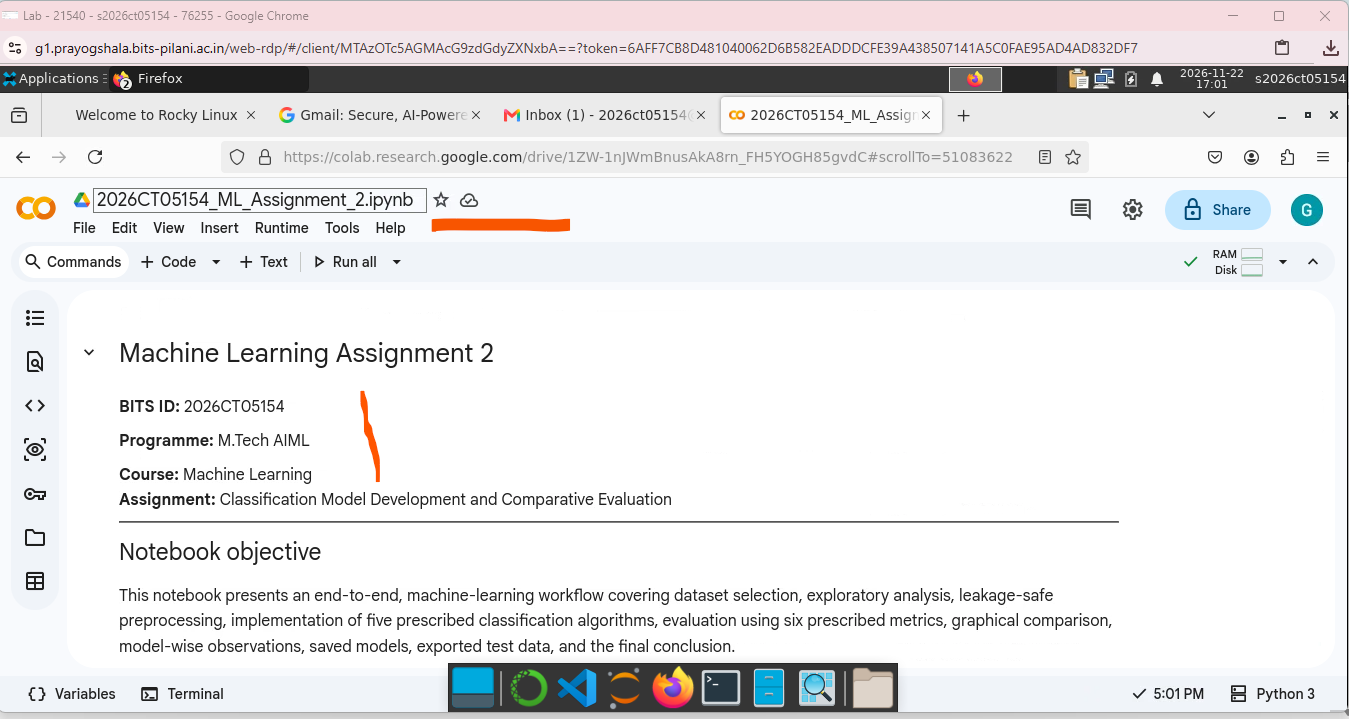


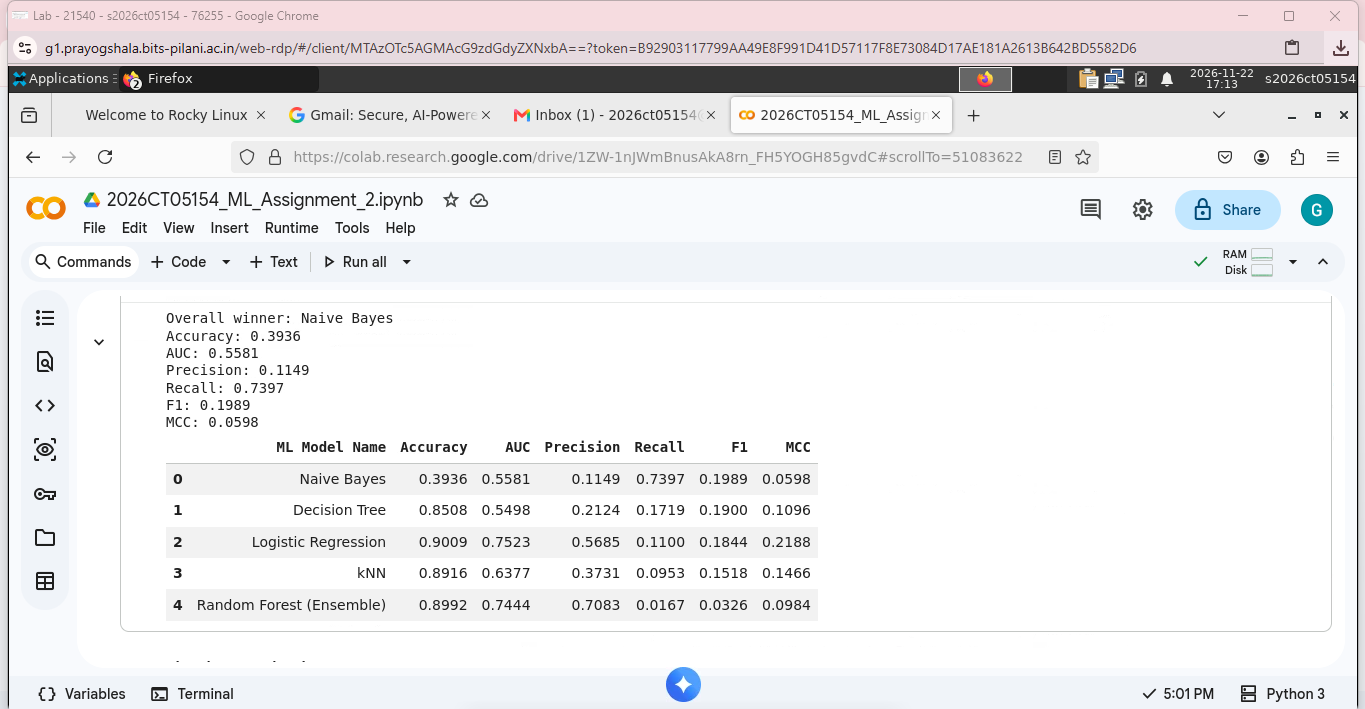

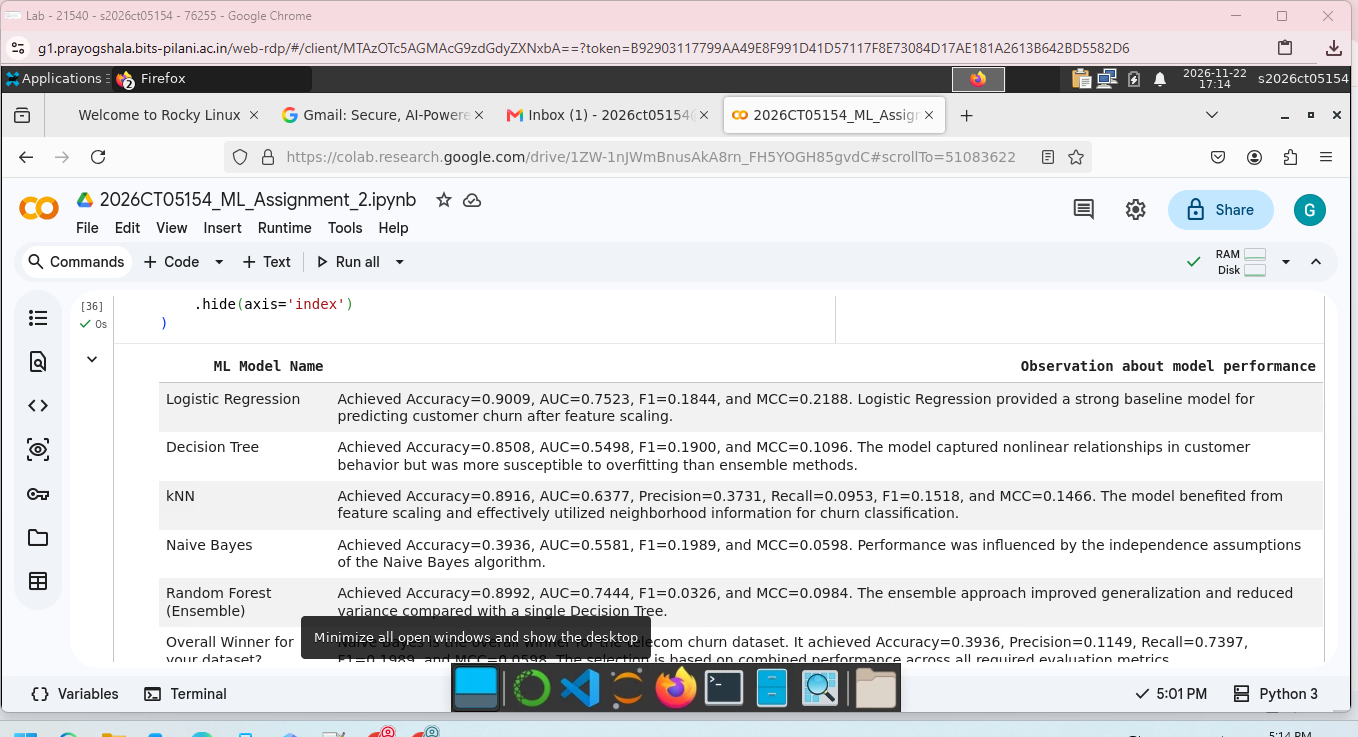

## 24. Final Execution Checklist

Before submitting:

- [ ] Run in BITS Virtual Lab.
- [ ] Confirm that every cell executes without an error.
- [ ] Confirm that the comparison table contains all five models and six metrics.
- [ ] Confirm that the all-metrics graph is readable.
- [ ] Confirm that five `.joblib` files were created.
- [ ] Confirm that `test_data.csv` was created.
- [ ] Capture a BITS Virtual Lab execution screenshot.
- [ ] Upload the notebook, requirements file, README, test data, model files, outputs, and screenshot to GitHub.
- [ ] Insert the final GitHub URL and Virtual Lab screenshot into the report/PDF.
- [ ] Verify the GitHub repository while signed out.
- [ ] Submit the final PDF.